# recursive-collapse-filter — Colab'da eğitim

Bu notebook deney hatlarını Colab GPU'sunda çalıştırır. **Tüm çıktılar Google Drive'a yazılır**, böylece
oturum kapansa bile kaybolmaz. Hücreleri yeniden çalıştırınca pipeline kaldığı nesilden devam eder.

Adım adım talimatlar: [COLAB.md](https://github.com/GuneyTunc/recursive-collapse-filter/blob/main/COLAB.md)

1. **Çalışma zamanı → Çalışma zamanı türünü değiştir → L4 GPU** (yoksa T4). TPU seçme.
2. Hücreleri sırayla çalıştır. Yalnızca **Ayarlar** hücresini düzenlemen gerekir.
3. Aynı tohum için hatları **sırayla** çalıştır: nesil-0 modeli tüm hatlarca paylaşılır.
   Aynı Drive klasörüne iki Colab oturumundan aynı anda yazma.

## 1. GPU kontrolü

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
import torch
print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available())
assert torch.cuda.is_available(), "GPU yok: Çalışma zamanı → Çalışma zamanı türünü değiştir → GPU"
major, minor = torch.cuda.get_device_capability()
print("compute capability", f"{major}.{minor}", "→ precision:", "bf16" if major >= 8 else "fp16 (T4)")

name, memory.total [MiB]
Tesla T4, 15360 MiB
torch 2.14.1+cu130 | CUDA: True
compute capability 7.5 → precision: fp16 (T4)


## 2. Ayarlar

In [2]:
REPO_URL = "https://github.com/GuneyTunc/recursive-collapse-filter.git"
BRANCH = "main"

DRIVE_ROOT = "/content/drive/MyDrive/recursive-collapse-filter"  # çıktılar, veri, rapor
LINES = ["raw"]          # sırayla çalışır: raw, dual_filter, human_mix, density_only, ppl_only, semdedup, dual_human, accumulate
SEEDS = [0]              # bir oturumda 1 tohum önerilir (~4 saat / hat)
EXTRA = [                # isteğe bağlı config değişiklikleri: "anahtar=değer"
    # "data.n_train=5000",       # süreyi yarıya indirir (tüm hatlarda aynı kullan!)
    # "generate.batch_size=256", # büyük VRAM'de daha hızlı üretim (yalnızca hız ayarı)
]

## 3. Drive ve kod

In [4]:
from google.colab import drive
drive.mount("/content/drive")

import os, pathlib
REPO_DIR = "/content/recursive-collapse-filter"
if pathlib.Path(REPO_DIR).exists():
    !git -C {REPO_DIR} fetch -q origin && git -C {REPO_DIR} checkout -q {BRANCH} && git -C {REPO_DIR} pull -q --ff-only
else:
    !git clone -q -b {BRANCH} {REPO_URL} {REPO_DIR}
%cd {REPO_DIR}
!git log --oneline -1

os.environ["MC_OUTPUT_DIR"] = f"{DRIVE_ROOT}/outputs"
os.environ["PYTHONIOENCODING"] = "utf-8"
DATA_DIR = f"{DRIVE_ROOT}/data/real"  # gerçek veri bir kez indirilir, sonraki oturumlar Drive'dan okur
pathlib.Path(DRIVE_ROOT).mkdir(parents=True, exist_ok=True)

Mounted at /content/drive
/content/recursive-collapse-filter
8118957 (HEAD -> main, origin/main, origin/heuristic-tolerance-interim-report, origin/HEAD) Update interim report (HTML and PDF)


## 4. Kurulum ve testler
Colab'ın kendi PyTorch'u kullanılır; yalnızca eksik paketler kurulur (~1 dk).

In [5]:
!pip install -q -r requirements.txt
!python -m pytest -q tests

........................................                                 [100%]
40 passed in 3.75s


## 5. (İsteğe bağlı) Duman testi
Birkaç dakikada uçtan uca çalışır. Yeni bir GPU türünde ilk kez çalıştırıyorsan önerilir.
Çıktıları `/content` altına yazar, Drive'a değil.

In [ ]:
!MC_OUTPUT_DIR=/content/outputs_smoke python -m src.pipeline --config configs/smoke.yaml \
    --set selection.method=dual --set experiment.line=smoke_dual

## 6. Eğitim
Uzun sürer. Oturum koparsa 3. hücreden itibaren yeniden çalıştır: tamamlanan nesiller atlanır.
İlerleme Drive'da `outputs/<hat>/run.log` dosyasına da yazılır.

In [6]:
import shlex
sets = " ".join(f"--set {shlex.quote(s)}" for s in [f"data.data_dir={DATA_DIR}", *EXTRA])
seeds = " ".join(map(str, SEEDS))
for line in LINES:
    print(f"===== {line} | seeds {seeds} =====")
    !python -m src.pipeline --config configs/lines/{line}.yaml --seeds {seeds} {sets}

===== raw | seeds 0 =====
15:27:15 INFO NumExpr defaulting to 8 threads.
15:27:17 INFO Streaming 200000 stories from roneneldan/TinyStories ...
15:27:17 WARNING Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
README.md: 100% 1.06k/1.06k [00:00<00:00, 3.12MB/s]
15:27:53 INFO Real data cached in /content/drive/MyDrive/recursive-collapse-filter/data/real (train=10000, val=1000, test=2000)
15:27:53 INFO [seed 0] gen 0: fine-tuning on real data
config.json: 100% 724/724 [00:00<00:00, 5.03MB/s]
tokenizer_config.json: 100% 3.69k/3.69k [00:00<00:00, 11.7MB/s]
vocab.json: 100% 801k/801k [00:00<00:00, 95.3MB/s]
merges.txt: 100% 466k/466k [00:00<00:00, 95.1MB/s]
special_tokens_map.json: 100% 831/831 [00:00<00:00, 6.18MB/s]
tokenizer.json: 100% 2.10M/2.10M [00:00<00:00, 147MB/s]

model.safetensors: downloading bytes:  20% 107M/538M [00:01<00:03, 116MB/s, 4.44MB/s  ]  
model.safetensors: reconstructing file:  

## 7. Rapor
Tüm hatların `metrics.json` dosyalarını toplar; tablo ve grafikler Drive'daki `results/` klasörüne yazılır.

Wrote 6 rows to /content/drive/MyDrive/recursive-collapse-filter/results


,line,generation,n_seeds,test_ppl_mean,distinct_2_mean,vendi_mean,rare_recall_mean
0,raw,0,1,5.191535,0.332221,26.989869,0.301353
1,raw,1,1,5.504944,0.331676,26.969151,0.277760
2,raw,2,1,5.658040,0.339739,27.992944,0.258257
3,raw,3,1,5.763246,0.336446,28.301832,0.247248
4,raw,4,1,5.850658,0.339766,28.590887,0.230261
5,raw,5,1,5.928991,0.341043,29.293203,0.200692


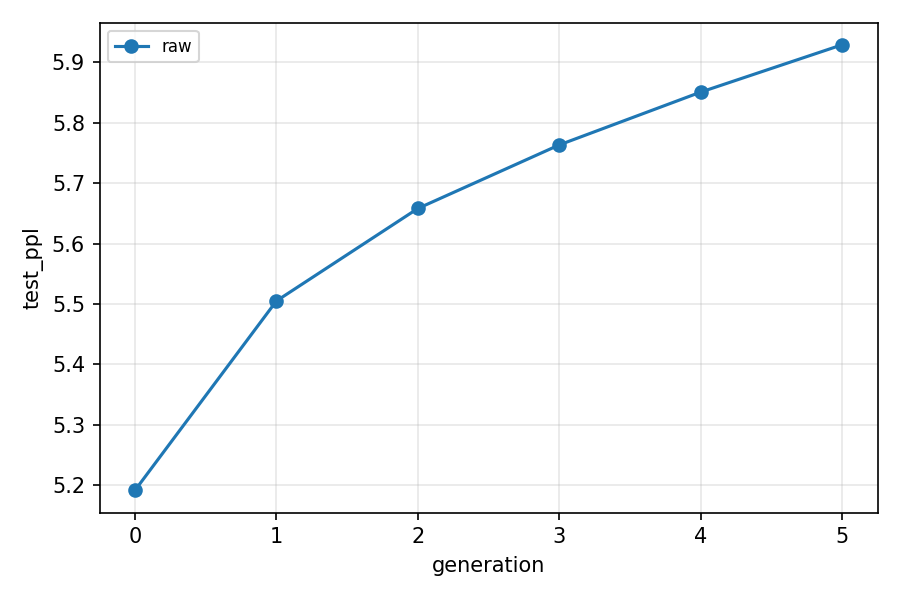

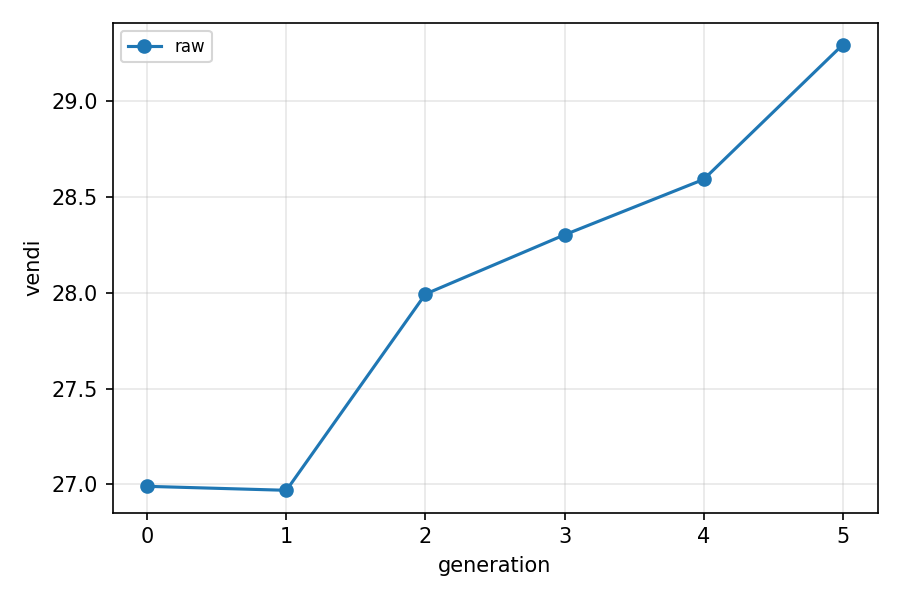

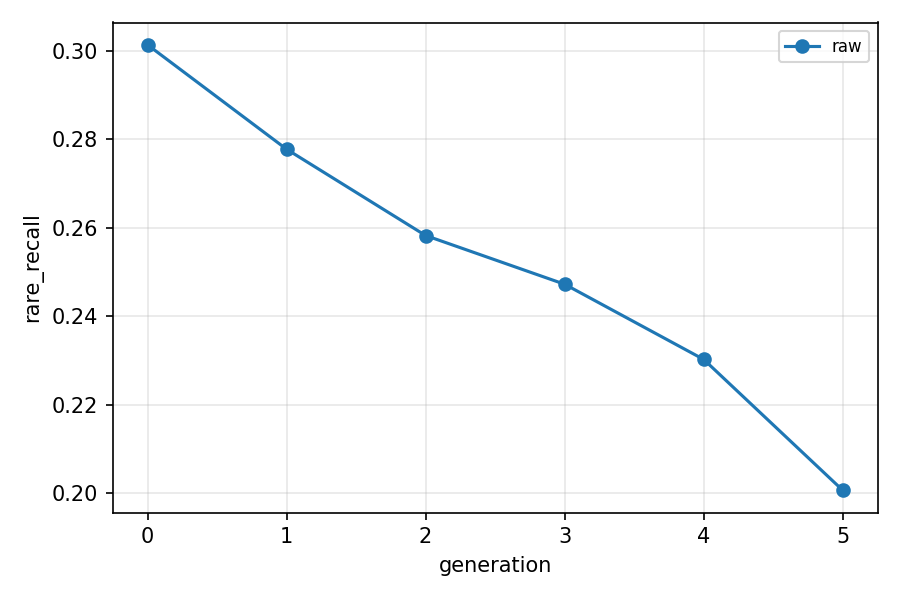

In [7]:
!python -m src.metrics.report --results {os.environ['MC_OUTPUT_DIR']} --out {DRIVE_ROOT}/results

import pandas as pd
from IPython.display import Image, display
summary = pd.read_csv(f"{DRIVE_ROOT}/results/summary.csv")
display(summary[["line", "generation", "n_seeds", "test_ppl_mean", "distinct_2_mean", "vendi_mean", "rare_recall_mean"]])
for metric in ["test_ppl", "vendi", "rare_recall"]:
    display(Image(f"{DRIVE_ROOT}/results/plots/{metric}.png"))

## 8. Süre ve kaynak kontrolü
Her neslin süreleri `metrics.json` içindeki `time_*` alanlarındadır. İlk nesilden sonra buna bakıp
oturum başına kaç nesil sığacağını hesapla.

In [8]:
import json, glob
for path in sorted(glob.glob(f"{os.environ['MC_OUTPUT_DIR']}/**/metrics.json", recursive=True)):
    m = json.load(open(path))
    times = {k: v for k, v in m.items() if k.startswith("time_")}
    print(path.split("outputs/")[-1], m.get("gpu"), m.get("precision"), f"{sum(times.values())/60:.1f} dk", times)

_shared/seed0/gen0/metrics.json Tesla T4 float16 30.9 dk {'time_train': 363.93, 'time_test_ppl': 13.9, 'time_generate': 1425.67, 'time_eval': 49.8}
raw/seed0/gen1/metrics.json Tesla T4 float16 30.6 dk {'time_features': 0.0, 'time_select': 0.0, 'time_train': 364.95, 'time_test_ppl': 13.82, 'time_generate': 1426.89, 'time_eval': 32.93}
raw/seed0/gen2/metrics.json Tesla T4 float16 30.6 dk {'time_features': 0.0, 'time_select': 0.0, 'time_train': 359.39, 'time_test_ppl': 13.83, 'time_generate': 1428.32, 'time_eval': 31.94}
raw/seed0/gen3/metrics.json Tesla T4 float16 30.9 dk {'time_features': 0.0, 'time_select': 0.0, 'time_train': 359.41, 'time_test_ppl': 13.89, 'time_generate': 1446.87, 'time_eval': 31.76}
raw/seed0/gen4/metrics.json Tesla T4 float16 30.2 dk {'time_features': 0.0, 'time_select': 0.0, 'time_train': 356.02, 'time_test_ppl': 13.83, 'time_generate': 1411.3, 'time_eval': 28.34}
raw/seed0/gen5/metrics.json Tesla T4 float16 8.0 dk {'time_features': 0.0, 'time_select': 0.0, 'time_